In [1]:
from ase.io import read
from ase.build import make_supercell
from matplotlib import rc

rc("text", usetex=True)
import matplotlib.pylab as pylab

params = {"legend.fontsize": "14", "axes.labelsize": 20, "axes.titlesize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16}
pylab.rcParams.update(params)
import numpy as np
import glob

try:
    from tqdm import tqdm as _tqdm

    _TQDM_AVAILABLE = True
except ImportError:
    _TQDM_AVAILABLE = False


def _progress(iterable, **kwargs):
    """Wrap an iterable with tqdm if available, else return as-is."""
    if _TQDM_AVAILABLE:
        return _tqdm(iterable, **kwargs)
    return iterable

In [3]:
# load the covariance matrix
traj_directory = "/Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/"
def cov_matrix_path(temp):
    if temp != 700:
        return f"{traj_directory}/{temp}_K/covariance_matrix.npy"
    else:
        return f"{traj_directory}/{temp}_K_rerun/covariance_matrix.npy"

def atom_resolved_eigen_vectors(temp=200, n_modes=10):
    # get the indices of of each elements (Li, P, S, Cl) in the supercell
    supercell = read(f"{traj_directory}/{temp}_K/CONTCAR")
    element_indices = {'Li': [], 'P': [], 'S': [], 'Cl': []}
    for i, atom in enumerate(supercell):
        element_indices[atom.symbol].append(i)  

    # now load the covariance matrix and compute its eigenvalues and eigenvectors
    cov_matrix = np.load(cov_matrix_path(temp))
    eigvals, eigvecs = np.linalg.eigh(cov_matrix)
    # sort the eigenvalues and eigenvectors in descending order
    idx = np.argsort(eigvals)[::-1]
    eigvals = eigvals[idx]
    eigvecs = eigvecs[:, idx]

    # now go through each eigenvector and compute the Cartesian norm of each atom's contribution to that eigenvector
    # such that for an eigenvector v with dimension 3N, it will be reshaped into a vector of dimension N, where each # entry is the Cartesian norm of the 3D vector corresponding to that atom's contribution to the eigenvector
    eigen_vectors_atom_contrib = {}
    for i in _progress(range(n_modes), desc="Computing atom-resolved eigenvectors"):
        _eigvec = eigvecs[:, i]
        eigen_vectors_atom_contrib[i] = {}
        for element, indices in element_indices.items():
            contributions = []
            for idx in indices:
                # get the 3D vector corresponding to this atom's contribution to the eigenvector
                vec_3d = _eigvec[idx * 3: (idx + 1) * 3]
                # compute the Cartesian norm of this vector
                norm = np.linalg.norm(vec_3d)
                contributions.append(norm)
            eigen_vectors_atom_contrib[i][element] = contributions
    return eigen_vectors_atom_contrib

def compute_atomic_contributions(eigen_vector_atom_contrib):
    #given an eigen_vectors_atom_contrib dictionary, compute the average contribution of each element to each eigenvector
    atomic_contributions = {}
    total = sum([sum(contribs) for contribs in eigen_vector_atom_contrib.values()])
    for element in eigen_vector_atom_contrib.keys():
        atomic_contributions[element] = sum(eigen_vector_atom_contrib[element])/total
    return atomic_contributions

In [4]:
n_modes = 10
eigen_vectors_atom_contrib_200K = atom_resolved_eigen_vectors(temp=200, n_modes=n_modes)
for i in range(n_modes):
    atomic_contributions = compute_atomic_contributions(eigen_vectors_atom_contrib_200K[i])
    print(f"Eigenvector {i}: {atomic_contributions}")

Computing atom-resolved eigenvectors: 100%|██████████| 10/10 [00:00<00:00, 1031.45it/s]

Eigenvector 0: {'Li': np.float64(0.05816579323973865), 'P': np.float64(0.47666019297846207), 'S': np.float64(0.0001450829315944266), 'Cl': np.float64(0.46502893085020486)}
Eigenvector 1: {'Li': np.float64(0.5943692350452758), 'P': np.float64(0.10540724196177964), 'S': np.float64(0.09328474670968111), 'Cl': np.float64(0.20693877628326346)}
Eigenvector 2: {'Li': np.float64(0.23837271247836722), 'P': np.float64(0.30342921032589965), 'S': np.float64(0.24791577293183992), 'Cl': np.float64(0.21028230426389324)}
Eigenvector 3: {'Li': np.float64(0.4248937377530669), 'P': np.float64(0.13197122089110866), 'S': np.float64(0.1561748457775839), 'Cl': np.float64(0.28696019557824054)}
Eigenvector 4: {'Li': np.float64(0.6056709042587008), 'P': np.float64(0.09034796460943549), 'S': np.float64(0.07290355837115935), 'Cl': np.float64(0.23107757276070434)}
Eigenvector 5: {'Li': np.float64(0.4582111532222784), 'P': np.float64(0.07288041464239438), 'S': np.float64(0.09173955817039119), 'Cl': np.float64(0.377

Computing atom-resolved eigenvectors: 100%|██████████| 10/10 [00:00<00:00, 303.92it/s]


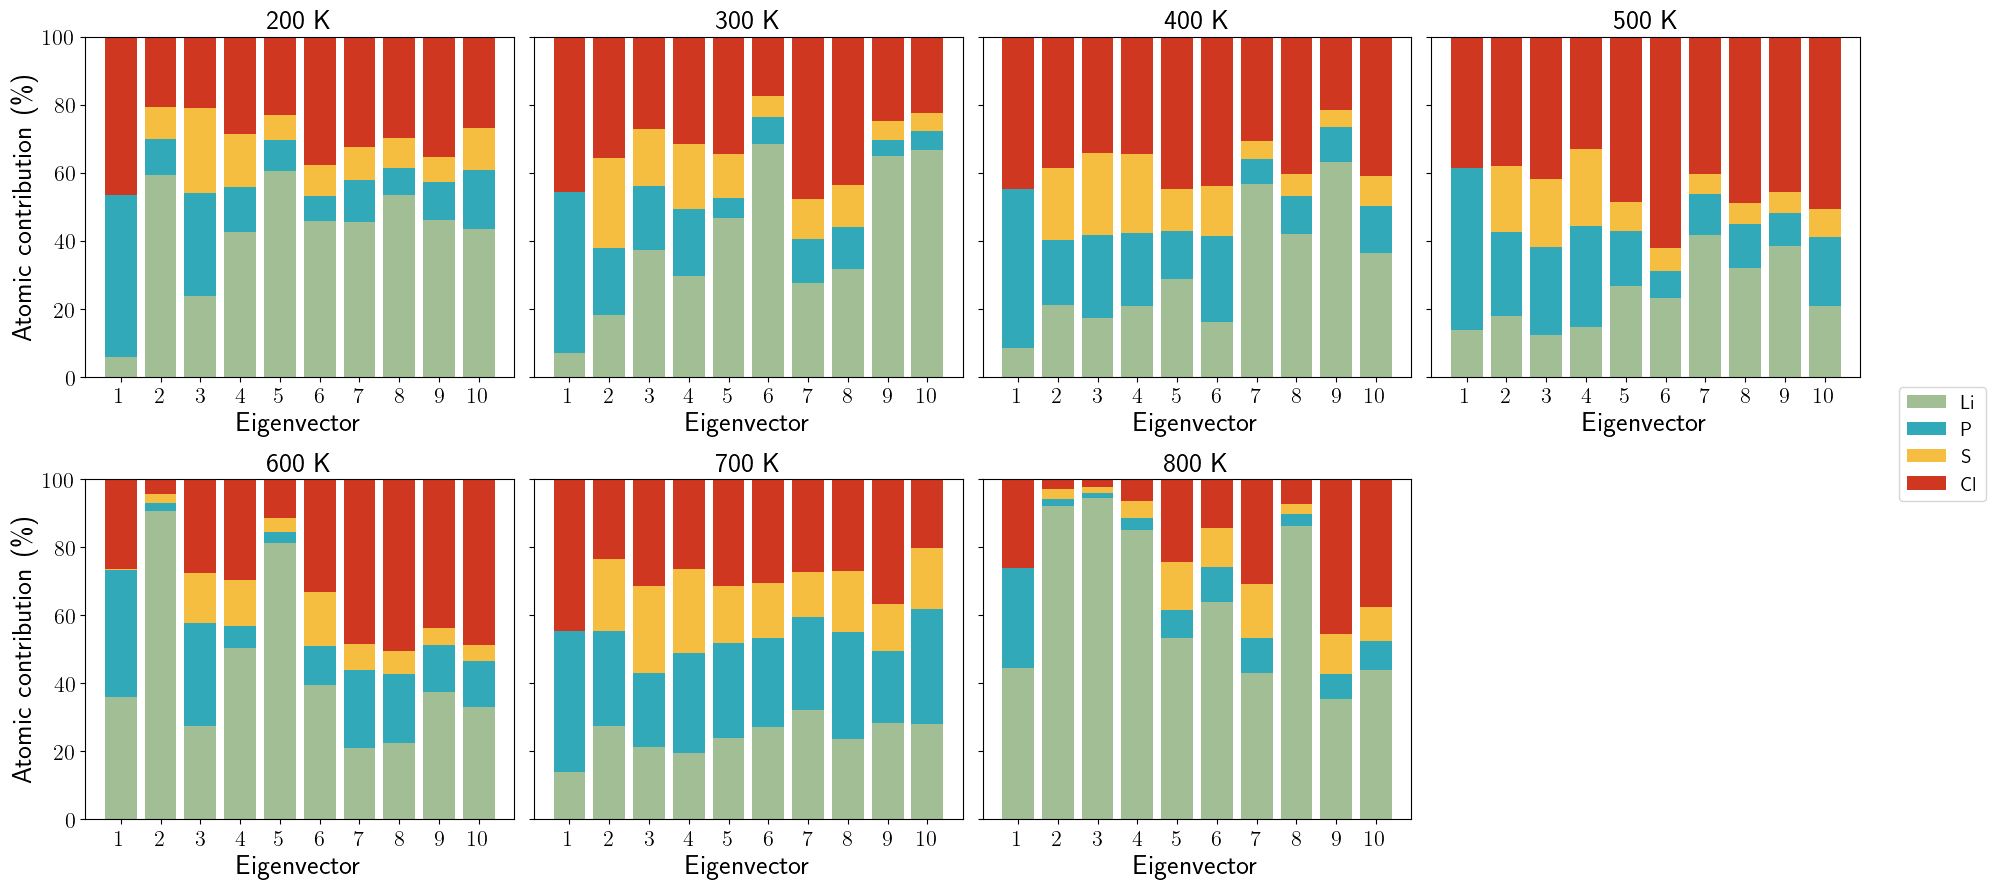

In [5]:
temperatures = range(200, 801, 100)
elements = ["Li", "P", "S", "Cl"]
contributions_by_temp = {}

for temp in temperatures:
    eigen_contrib = atom_resolved_eigen_vectors(temp=temp, n_modes=n_modes)
    contributions_by_temp[temp] = [
        compute_atomic_contributions(eigen_contrib[mode])
        for mode in range(n_modes)
    ]

fig, axes = pylab.subplots(2, 4, figsize=(20, 9), sharey=True)
axes = axes.ravel()
colors = ["#A1BE95", "#31a9b8", "#f5be41", "#cf3721"]

for ax, temp in zip(axes, temperatures):
    bottom = np.zeros(n_modes)

    for element, color in zip(elements, colors):
        values = np.array([
            mode_contrib[element] * 100
            for mode_contrib in contributions_by_temp[temp]
        ])
        ax.bar(np.arange(1, n_modes + 1), values, bottom=bottom,
               label=element, color=color)
        bottom += values

    ax.set_title(f"{temp} K")
    ax.set_xlabel("Eigenvector")
    ax.set_xticks(np.arange(1, n_modes + 1))
    ax.set_ylim(0, 100)


axes[0].set_ylabel("Atomic contribution (\\%)")
axes[4].set_ylabel("Atomic contribution (\\%)")

axes[-1].set_visible(False)
fig.legend(elements, loc="center right")
fig.tight_layout(rect=[0, 0, 0.94, 1])
pylab.savefig(
    "/Users/jackyang-macmini/Dropbox/Documents/projects/artificial_intelligence/LiPSCl-diffusion-documents/nve_md_essential_dynamics_analysis_Li_framework_svd_atom_contributions.pdf",
    bbox_inches="tight",
)
pylab.show()